### Preprocess and Feature Extraction

In [1]:
import matplotlib.pyplot as plt

In [16]:
import pandas as pd
import numpy as np
import os
import re
import librosa
import librosa.display
import matplotlib.pyplot as plt
import soundfile as sf

import noisereduce as nr  
from scipy.signal import butter, filtfilt

from concurrent.futures import ThreadPoolExecutor, as_completed
import multiprocessing
from tqdm import tqdm

DATA_PATH = '..\dataset\HW1_M'

In [3]:
metadata = pd.read_csv('metadata.csv')

In [4]:
metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 822 entries, 0 to 821
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   filename         822 non-null    object
 1   question_number  822 non-null    object
 2   student_id       822 non-null    object
 3   gender           822 non-null    object
 4   path             822 non-null    object
 5   has_intro        822 non-null    int64 
dtypes: int64(1), object(5)
memory usage: 38.7+ KB


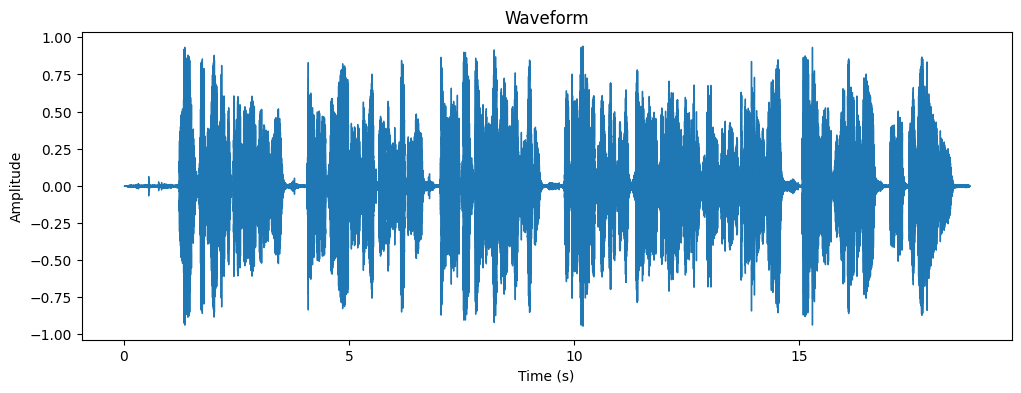

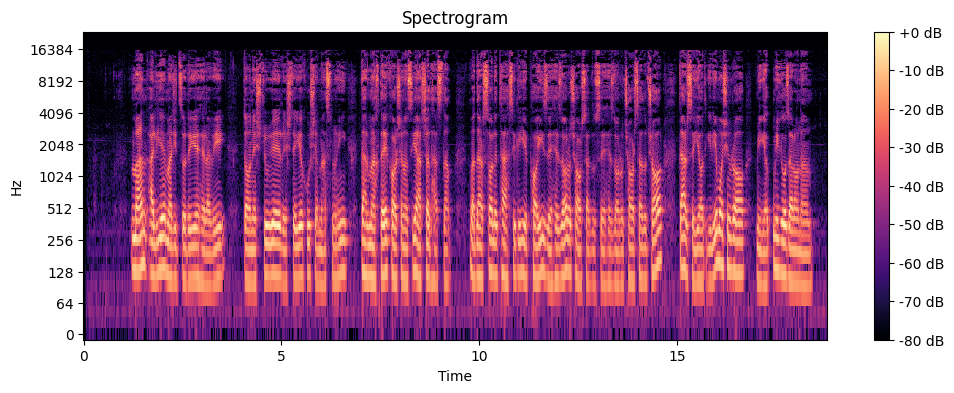

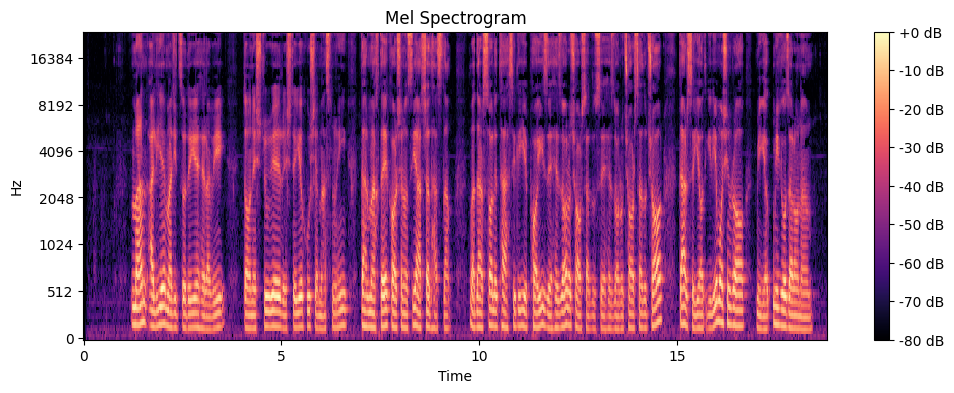

In [5]:
audio_path = metadata['path'][0]

y, sr = librosa.load(audio_path, sr=None)

# **1. Display Waveform**
plt.figure(figsize=(12, 4))
librosa.display.waveshow(y, sr=sr)
plt.title("Waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

# **2. Compute and display Spectrogram**
D = np.abs(librosa.stft(y))  # Compute STFT
plt.figure(figsize=(12, 4))
librosa.display.specshow(librosa.amplitude_to_db(D, ref=np.max), sr=sr, x_axis="time", y_axis="log")
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram")
plt.show()

# **3. Compute and display Mel Spectrogram**
mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(mel_spec_db, sr=sr, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram")
plt.show()


In [6]:
print("Sample rate: ", sr)  

Sample rate:  48000


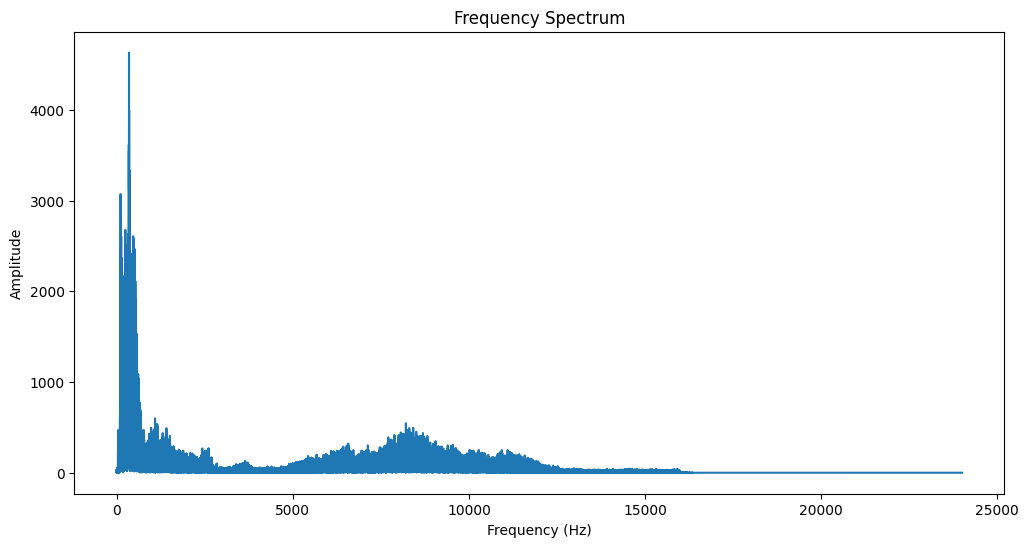

In [7]:
# Calculate the Fast Fourier Transform (FFT)
fft_spectrum = np.fft.fft(y)
frequencies = np.fft.fftfreq(len(fft_spectrum), 1/sr)

# Plot the frequency spectrum
plt.figure(figsize=(12, 6))
plt.plot(frequencies[:len(frequencies)//2], np.abs(fft_spectrum)[:len(fft_spectrum)//2])
plt.title("Frequency Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.show()

In [8]:
female_sample = metadata[metadata['gender'] == 'female'].iloc[0]    

..\dataset\HW1_M\HW1_intro_610300070_female.mp3


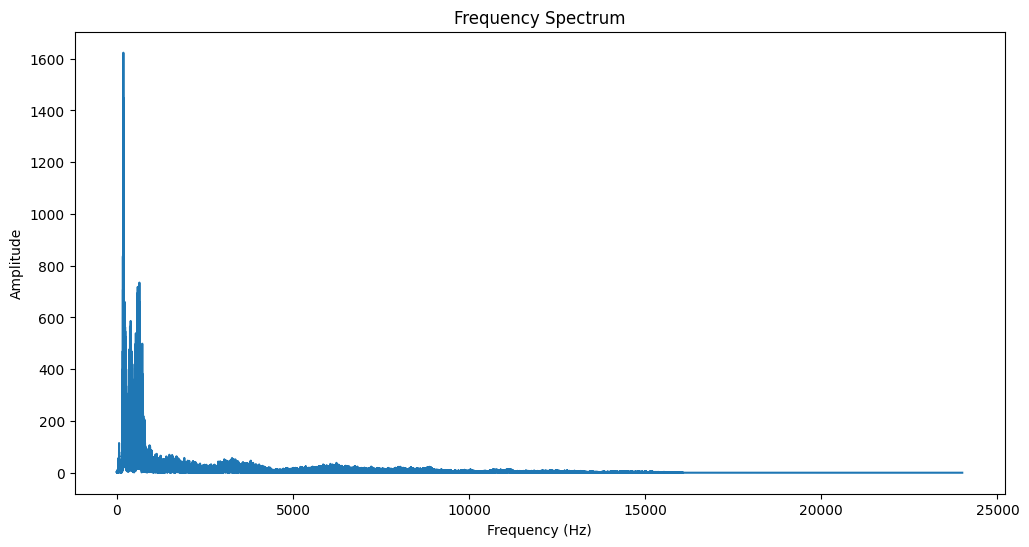

In [9]:
audio_path = female_sample['path']
print(audio_path)
y, sr = librosa.load(audio_path, sr=None)
# Calculate the Fast Fourier Transform (FFT)
fft_spectrum = np.fft.fft(y)
frequencies = np.fft.fftfreq(len(fft_spectrum), 1/sr)

# Plot the frequency spectrum
plt.figure(figsize=(12, 6))
plt.plot(frequencies[:len(frequencies)//2], np.abs(fft_spectrum)[:len(fft_spectrum)//2])
plt.title("Frequency Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.show()

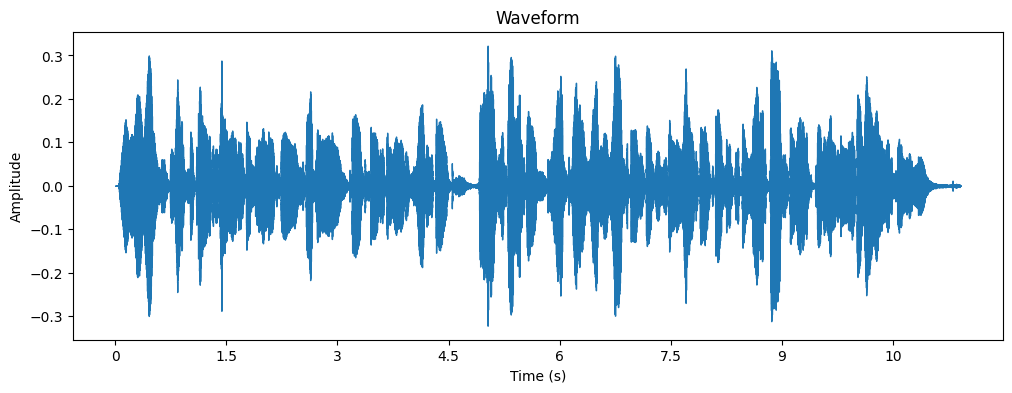

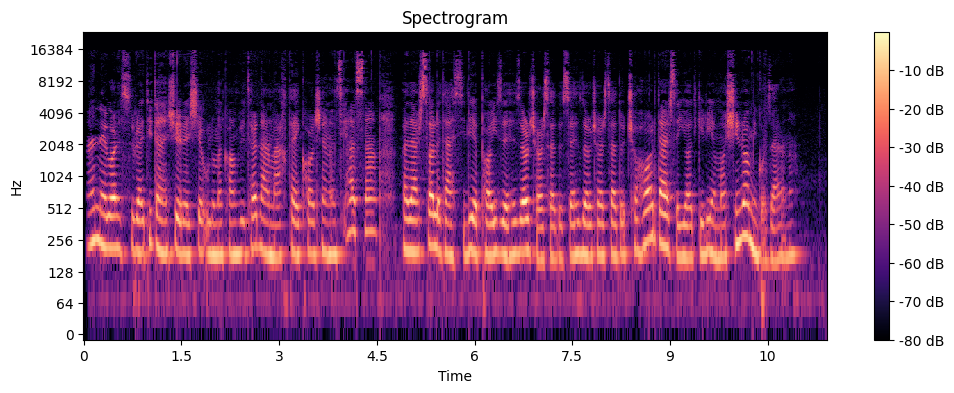

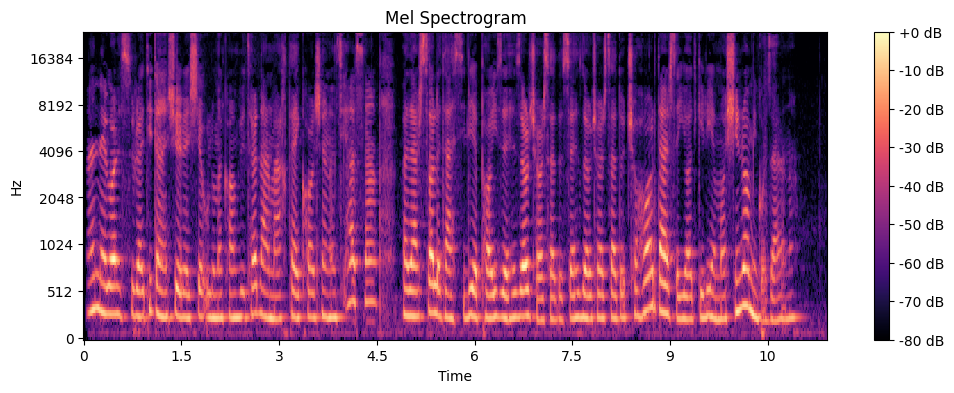

In [10]:
plt.figure(figsize=(12, 4))
librosa.display.waveshow(y, sr=sr)
plt.title("Waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

# **2. Compute and display Spectrogram**
D = np.abs(librosa.stft(y))  # Compute STFT
plt.figure(figsize=(12, 4))
librosa.display.specshow(librosa.amplitude_to_db(D, ref=np.max), sr=sr, x_axis="time", y_axis="log")
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram")
plt.show()

# **3. Compute and display Mel Spectrogram**
mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(mel_spec_db, sr=sr, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram")
plt.show()


In [11]:
print("Sample rate: ", sr)

Sample rate:  48000


In [26]:
for index, data in metadata.iterrows():
    path = data['path']
    y, sr = librosa.load(path, sr=None)
    print("index: ", index, "sample rate: ", sr)
    metadata.at[index, 'sample_rate'] = sr

index:  0 sample rate:  48000
index:  1 sample rate:  48000
index:  2 sample rate:  48000
index:  3 sample rate:  48000
index:  4 sample rate:  48000
index:  5 sample rate:  48000
index:  6 sample rate:  48000
index:  7 sample rate:  48000
index:  8 sample rate:  48000
index:  9 sample rate:  48000
index:  10 sample rate:  48000
index:  11 sample rate:  44100
index:  12 sample rate:  48000
index:  13 sample rate:  44100
index:  14 sample rate:  48000
index:  15 sample rate:  48000
index:  16 sample rate:  48000
index:  17 sample rate:  48000
index:  18 sample rate:  48000
index:  19 sample rate:  44100
index:  20 sample rate:  48000
index:  21 sample rate:  44100
index:  22 sample rate:  44100
index:  23 sample rate:  48000
index:  24 sample rate:  48000
index:  25 sample rate:  44100
index:  26 sample rate:  44100
index:  27 sample rate:  44100
index:  28 sample rate:  44100
index:  29 sample rate:  48000
index:  30 sample rate:  48000
index:  31 sample rate:  44100
index:  32 sample 

In [15]:
metadata['sample_rate'].value_counts()

KeyError: 'sample_rate'

In [28]:
print(metadata[metadata['sample_rate'] == 24000])

                      filename question_number student_id gender  \
288  HW1_Q2_810103057_male.mp3              Q2  810103057   male   

                                           path  has_intro  sample_rate  
288  ..\dataset\HW1_M\HW1_Q2_810103057_male.mp3          1      24000.0  


In [16]:
import shutil

In [31]:
TARGET_SAMPLE_RATE = 44100  # Choose 44100 Hz as the standard rate

def resample_audio(input_path, output_path, target_sr=TARGET_SAMPLE_RATE):
    """Resamples an audio file to the target sample rate and saves it."""
    sr = metadata[metadata['path'] == input_path]['sample_rate'].values[0]
    if sr != target_sr:
        y, sr = librosa.load(input_path, sr=None)
        y_resampled = librosa.resample(y, orig_sr=sr, target_sr=target_sr)
        sf.write(output_path, y_resampled, target_sr)  # Save resampled file
        print(f"Resampled: {input_path} -> {output_path}")
    else:
        shutil.copy(input_path, output_path)
        print(f"Already at target sample rate: {input_path}")

# Example usage (loop over dataset)
dataset_path = "..\dataset\HW1_M"
output_directory = "..\dataset\HW1_M_resampled"

os.makedirs(output_directory, exist_ok=True)

for filename in os.listdir(dataset_path):
    if filename.endswith(".mp3"):
        input_file = os.path.join(dataset_path, filename)
        output_file = os.path.join(output_directory, filename)
        resample_audio(input_file, output_file)


Resampled: ..\dataset\HW1_M\HW1-intro-810103226-male.mp3 -> ..\dataset\HW1_M_resampled\HW1-intro-810103226-male.mp3
Resampled: ..\dataset\HW1_M\HW1-intro-810801075-male.mp3 -> ..\dataset\HW1_M_resampled\HW1-intro-810801075-male.mp3
Resampled: ..\dataset\HW1_M\HW1-intro-Student-810101423_male.mp3 -> ..\dataset\HW1_M_resampled\HW1-intro-Student-810101423_male.mp3
Resampled: ..\dataset\HW1_M\HW1-Q1-1-810103226-male.mp3 -> ..\dataset\HW1_M_resampled\HW1-Q1-1-810103226-male.mp3
Resampled: ..\dataset\HW1_M\HW1-Q1-2-810103226-male.mp3 -> ..\dataset\HW1_M_resampled\HW1-Q1-2-810103226-male.mp3
Resampled: ..\dataset\HW1_M\HW1-Q1-3-810103226-male.mp3 -> ..\dataset\HW1_M_resampled\HW1-Q1-3-810103226-male.mp3
Resampled: ..\dataset\HW1_M\HW1-Q1-810801075-male.mp3 -> ..\dataset\HW1_M_resampled\HW1-Q1-810801075-male.mp3
Resampled: ..\dataset\HW1_M\HW1-Q2-1-810103226-male.mp3 -> ..\dataset\HW1_M_resampled\HW1-Q2-1-810103226-male.mp3
Resampled: ..\dataset\HW1_M\HW1-Q2-2-810103226-male.mp3 -> ..\dataset\

In [32]:
for index, data in metadata.iterrows():
    path = data['path']
    path = path.replace("HW1_M", "HW1_M_resampled")
    y, sr = librosa.load(path, sr=None)
    # Calculate the Fast Fourier Transform (FFT)
    print("index: ", index, "sample rate: ", sr)
    metadata.at[index, 'sample_rate_resampled'] = sr

index:  0 sample rate:  44100
index:  1 sample rate:  44100
index:  2 sample rate:  44100
index:  3 sample rate:  44100
index:  4 sample rate:  44100
index:  5 sample rate:  44100
index:  6 sample rate:  44100
index:  7 sample rate:  44100
index:  8 sample rate:  44100
index:  9 sample rate:  44100
index:  10 sample rate:  44100
index:  11 sample rate:  44100
index:  12 sample rate:  44100
index:  13 sample rate:  44100
index:  14 sample rate:  44100
index:  15 sample rate:  44100
index:  16 sample rate:  44100
index:  17 sample rate:  44100
index:  18 sample rate:  44100
index:  19 sample rate:  44100
index:  20 sample rate:  44100
index:  21 sample rate:  44100
index:  22 sample rate:  44100
index:  23 sample rate:  44100
index:  24 sample rate:  44100
index:  25 sample rate:  44100
index:  26 sample rate:  44100
index:  27 sample rate:  44100
index:  28 sample rate:  44100
index:  29 sample rate:  44100
index:  30 sample rate:  44100
index:  31 sample rate:  44100
index:  32 sample 

In [33]:
metadata['sample_rate_resampled'].value_counts()

sample_rate_resampled
44100.0    822
Name: count, dtype: int64

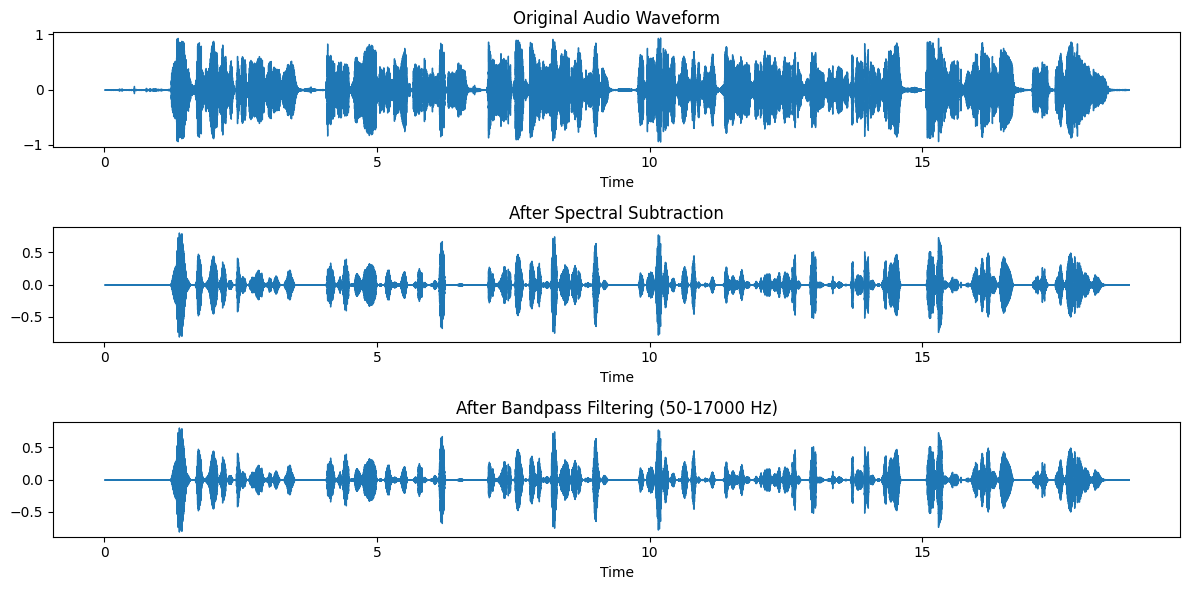

In [12]:
audio_path = metadata['path'][0]
# audio_path = female_sample['path']
y, sr = librosa.load(audio_path, sr=None)

denoised_audio = nr.reduce_noise(y=y, sr=sr, stationary=False)

def butter_bandpass(lowcut, highcut, sr, order=5):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype="band")
    return b, a

def apply_bandpass(y, sr, lowcut=50, highcut=17000):
    """Filters out frequencies outside human speech range."""
    b, a = butter_bandpass(lowcut, highcut, sr)
    return filtfilt(b, a, y)

final_audio = apply_bandpass(denoised_audio, sr)

plt.figure(figsize=(12, 6))

plt.subplot(3, 1, 1)
librosa.display.waveshow(y, sr=sr)
plt.title("Original Audio Waveform")

plt.subplot(3, 1, 2)
librosa.display.waveshow(denoised_audio, sr=sr)
plt.title("After Spectral Subtraction")

plt.subplot(3, 1, 3)
librosa.display.waveshow(final_audio, sr=sr)
plt.title("After Bandpass Filtering (50-17000 Hz)")

plt.tight_layout()
plt.show()
  
sf.write("cleaned_audio.wav", final_audio, sr)


In [13]:
def denoise_audio(audio_path, output_path, lowcut=50, highcut=17000):
    if os.path.exists(output_path):
        print(f"Skipped: {output_path} already exists")
        return 
    y, sr = librosa.load(audio_path, sr=None)
    denoised_audio = nr.reduce_noise(y=y, sr=sr, stationary=False)
    final_audio = apply_bandpass(denoised_audio, sr, lowcut=lowcut, highcut=highcut)
    sf.write(output_path, final_audio, sr)
    print(f"Denoised and saved: {output_path}")
    
# Example usage (loop over dataset)
output_directory = "..\dataset\HW1_M_cleaned"
input_directory = "..\dataset\HW1_M_resampled"
count = 0
for filename in os.listdir(input_directory):
    if filename.endswith(".mp3"):
        print(count)
        input_file = os.path.join(input_directory, filename)
        output_file = os.path.join(output_directory, filename)
        denoise_audio(input_file, output_file)
        count += 1

0
Skipped: ..\dataset\HW1_M_cleaned\HW1-intro-810103226-male.mp3 already exists
1
Skipped: ..\dataset\HW1_M_cleaned\HW1-intro-810801075-male.mp3 already exists
2
Skipped: ..\dataset\HW1_M_cleaned\HW1-intro-Student-810101423_male.mp3 already exists
3
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q1-1-810103226-male.mp3 already exists
4
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q1-2-810103226-male.mp3 already exists
5
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q1-3-810103226-male.mp3 already exists
6
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q1-810801075-male.mp3 already exists
7
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q2-1-810103226-male.mp3 already exists
8
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q2-2-810103226-male.mp3 already exists
9
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q2-3-810103226-male.mp3 already exists
10
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q2-810801075-male.mp3 already exists
11
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q3-810103226-male.mp3 already exists
12
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q3-8

In [15]:
# Directories
INPUT_DIRECTORY = "../dataset/HW1_M_resampled"
OUTPUT_DIRECTORY = "../dataset/HW1_M_cleaned"

# Ensure output directory exists
os.makedirs(OUTPUT_DIRECTORY, exist_ok=True)

# Bandpass filter function
def apply_bandpass(y, sr, lowcut=50, highcut=17000):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(4, [low, high], btype="band")
    return filtfilt(b, a, y)

# Denoising function
def denoise_audio(file_name):
    input_path = os.path.join(INPUT_DIRECTORY, file_name)
    output_path = os.path.join(OUTPUT_DIRECTORY, file_name)

    # Skip if already processed
    if os.path.exists(output_path):
        return f"Skipped: {file_name}"

    try:
        # Load audio
        y, sr = librosa.load(input_path, sr=None)

        # Apply noise reduction
        denoised_audio = nr.reduce_noise(y=y, sr=sr, stationary=False)

        # Apply bandpass filtering
        final_audio = apply_bandpass(denoised_audio, sr)

        # Save the processed file
        sf.write(output_path, final_audio, sr)

        return f"Processed: {file_name}"

    except Exception as e:
        return f"Error processing {file_name}: {e}"

# Parallel processing function
def process_all_audio():
    audio_files = [f for f in os.listdir(INPUT_DIRECTORY) if f.endswith(".mp3")]

    # Use ThreadPoolExecutor for I/O-bound tasks
    with ThreadPoolExecutor(max_workers=8) as executor:  # Adjust max_workers if needed
        future_to_file = {executor.submit(denoise_audio, file): file for file in audio_files}

        # Track progress with tqdm
        for future in tqdm(as_completed(future_to_file), total=len(audio_files)):
            print(future.result())

# Run the parallel processing
if __name__ == "__main__":
    process_all_audio()


100%|██████████| 822/822 [00:00<00:00, 24174.49it/s]

Skipped: HW1_Q1.1_810199459_male.mp3
Skipped: HW1_intro_810103146_male.mp3
Skipped: HW1-Q2-3-810103226-male.mp3
Skipped: HW1.Q2b.810102087_female.mp3
Skipped: HW1_intro_MohammadJavadMousavi-810102263_male.mp3
Skipped: HW1_intro_810100269_male.mp3
Skipped: HW1_intro_810103145_male.mp3
Skipped: HW1_intro_810899073_male.mp3
Skipped: HW1_intro_810103140_male.mp3
Skipped: HW1-Q4-810801075-male.mp3
Skipped: HW1_into_810103322_male.mp3
Skipped: HW1_intro_810801072_Male.mp3
Skipped: HW1_intro_810103136_male.mp3
Skipped: HW1.Q4a.810102087_female.mp3
Skipped: HW1_intro_810100222_female.mp3
Skipped: HW1_intro_810800024_female.mp3
Skipped: HW1_Intro_810100217.mp3
Skipped: HW1_intro_810103123_female.mp3
Skipped: HW1_intro_810600133_female.mp3
Skipped: HW1_Q1_810101413_male.mp3
Skipped: HW1_intro_810100198_male.mp3
Skipped: HW1_intro_810103112_male.mp3
Skipped: HW1_intro_810600097_female.mp3
Skipped: HW1_Q1_810101401_male.mp3
Skipped: HW1_intro_810103108_male.mp3
Skipped: HW1.Q4j.810102087_female.mp

### Frame Segmentation (Windowing)

In [ ]:
# Define paths
DATA_PATH = "../dataset/HW1_M"
SAVE_PATH = "../processed_data"

# Ensure the save directory exists
os.makedirs(SAVE_PATH, exist_ok=True)

# Window size and hop length
WINDOW_SIZE = 1024  # Adjust based on need
HOP_LENGTH = 512    # Overlap between frames

def process_audio(file_path):
    """
    Load, normalize, apply windowing, and save frames for a given audio file.
    """
    try:
        # Load audio file
        y, sr = librosa.load(file_path, sr=None)

        # Normalize audio
        y = y / np.max(np.abs(y))

        # Apply windowing
        frames = librosa.util.frame(y, frame_length=WINDOW_SIZE, hop_length=HOP_LENGTH)

        # Save the processed data
        file_name = os.path.basename(file_path).replace(".mp3", ".npy")
        np.save(os.path.join(SAVE_PATH, file_name), frames)

        return file_path, frames.shape  # Return shape info for debugging

    except Exception as e:
        return file_path, f"Error: {str(e)}"


def process_all_audio():
    """
    Process all audio files in the dataset using multiprocessing.
    """
    # Get all audio file paths
    audio_files = [os.path.join(DATA_PATH, f) for f in os.listdir(DATA_PATH) if f.endswith(".mp3")]

    # Use multiprocessing to process files in parallel
    with multiprocessing.Pool(processes=multiprocessing.cpu_count()) as pool:
        results = list(tqdm(pool.imap(denoise_audio, audio_files), total=len(audio_files)))

    # Print summary
    for file, info in results:
        print(f"Processed: {file} -> {info}")

# Run the parallel processing
if __name__ == "__main__":
    process_all_audio()


In [64]:
SAMPLE_RATE = 44100  # Standard sample rate
WINDOW_SIZE = int(SAMPLE_RATE * 0.1)  # 100 ms window
HOP_LENGTH = WINDOW_SIZE // 2  # 50% overlap

file_path = metadata['path'][0] 
y, sr = librosa.load(file_path, sr=None)
# Normalize audio
y = y / np.max(np.abs(y))
# Apply windowing
frames = librosa.util.frame(y, frame_length=WINDOW_SIZE, hop_length=HOP_LENGTH)
frames = frames.T  # Transpose to have shape (n_frames, frame_length)
# Save the processed data
# file_name = os.path.basename(file_path).replace(".mp3", ".npy")
file_name = "test.npy"
np.save(file_name, frames)

In [65]:
frames = np.load("test.npy")  
print(frames.shape)

(408, 4410)


In [68]:
frames = np.load("test.npy")    # Shape: (num_frames, window_size)
ENERGY_THRESHOLD = 100  # Adjust this based on your data
NUM_SELECTED_WINDOWS = 10  # Keep only 50 important frames per file
# Compute energy for each frame
frame_energy = np.array([np.sum(frame**2) for frame in frames])
# Select frames where energy is above a threshold (i.e., contains speech)
voiced_frames = frames[frame_energy > ENERGY_THRESHOLD]
print(voiced_frames.shape)
# If too many frames remain, select NUM_SELECTED_WINDOWS evenly
if len(voiced_frames) > NUM_SELECTED_WINDOWS:
    indices = np.linspace(0, len(voiced_frames) - 1, NUM_SELECTED_WINDOWS, dtype=int)
    voiced_frames = voiced_frames[indices]
# Save selected frames
np.save("test.npy", voiced_frames)
print("Selected frames shape:", voiced_frames.shape)

(178, 4410)
Selected frames shape: (10, 4410)


In [70]:
INPUT_DIRECTORY = "../dataset/HW1_M_cleaned"
OUTPUT_DIRECTORY = "../dataset/HW1_M_windows"
SAMPLE_RATE = 44100  
WINDOW_SIZE = int(SAMPLE_RATE * 0.1)  # 100 ms window
HOP_LENGTH = WINDOW_SIZE // 2  # 50% overlap

os.makedirs(OUTPUT_DIRECTORY, exist_ok=True)

ENERGY_THRESHOLD = 100  
NUM_SELECTED_WINDOWS = 10 

def framing_and_normalizing(file_name):
    input_path = os.path.join(INPUT_DIRECTORY, file_name)
    output_path = os.path.join(OUTPUT_DIRECTORY, file_name.replace(".npy", ".mp3"))

    if os.path.exists(output_path):
        return f"Skipped: {file_name}"

    try:
        y, sr = librosa.load(file_path, sr=None)
        
        y = y / np.max(np.abs(y))
        
        frames = librosa.util.frame(y, frame_length=WINDOW_SIZE, hop_length=HOP_LENGTH)
        frames = frames.T  # Transpose to have shape (n_frames, frame_leng
        
        # frames = np.load(input_path)  

        # Compute energy for each frame
        frame_energy = np.array([np.sum(frame**2) for frame in frames])

        # Select frames where energy is above a threshold (i.e., contains speech)
        voiced_frames = frames[frame_energy > ENERGY_THRESHOLD]

        # If too many frames remain, select NUM_SELECTED_WINDOWS evenly
        if len(voiced_frames) > NUM_SELECTED_WINDOWS:
            indices = np.linspace(0, len(voiced_frames) - 1, NUM_SELECTED_WINDOWS, dtype=int)
            voiced_frames = voiced_frames[indices]

        # Save selected frames
        np.save(output_path, voiced_frames)

        return f"Processed: {file_name} ({len(voiced_frames)} frames kept)"

    except Exception as e:
        return f"Error processing {file_name}: {e}"

def process_all_files():
    audio_files = [f for f in os.listdir(INPUT_DIRECTORY) if f.endswith(".mp3")]

    for file in tqdm(audio_files):
        print(framing_and_normalizing(file))

if __name__ == "__main__":
    process_all_files()


  0%|          | 4/822 [00:00<00:24, 33.17it/s]

Processed: HW1-intro-810103226-male.mp3 (10 frames kept)
Processed: HW1-intro-810801075-male.mp3 (10 frames kept)
Processed: HW1-intro-Student-810101423_male.mp3 (10 frames kept)
Processed: HW1-Q1-1-810103226-male.mp3 (10 frames kept)
Processed: HW1-Q1-2-810103226-male.mp3 (10 frames kept)
Processed: HW1-Q1-3-810103226-male.mp3 (10 frames kept)
Processed: HW1-Q1-810801075-male.mp3 (10 frames kept)


  1%|▏         | 12/822 [00:00<00:25, 31.39it/s]

Processed: HW1-Q2-1-810103226-male.mp3 (10 frames kept)
Processed: HW1-Q2-2-810103226-male.mp3 (10 frames kept)
Processed: HW1-Q2-3-810103226-male.mp3 (10 frames kept)
Processed: HW1-Q2-810801075-male.mp3 (10 frames kept)
Processed: HW1-Q3-810103226-male.mp3 (10 frames kept)
Processed: HW1-Q3-810801075-male.mp3 (10 frames kept)
Processed: HW1-Q4-1-810103226-male.mp3 (10 frames kept)
Processed: HW1-Q4-2-810103226-male.mp3 (10 frames kept)


  3%|▎         | 21/822 [00:00<00:21, 36.52it/s]

...

Processed: HW1_Q6_810199459_male.mp3 (10 frames kept)
Processed: HW1_Q6_810199489_female.mp3 (10 frames kept)
Processed: HW1_Q6_810199569_male.mp3 (10 frames kept)
Processed: HW1_Q6_810199570_female.mp3 (10 frames kept)
Processed: HW1_Q6_810202047_male.mp3 (10 frames kept)
Processed: HW1_Q6_810600065_female.mp3.mp3 (10 frames kept)
Processed: HW1_Q6_810600072_male.mp3 (10 frames kept)
Processed: HW1_Q6_810600088_female.mp3 (10 frames kept)


100%|█████████▉| 818/822 [00:24<00:00, 36.10it/s]

Processed: HW1_Q6_810600097_female.mp3 (10 frames kept)
Processed: HW1_Q6_810600125_male.mp3 (10 frames kept)
Processed: HW1_Q6_810600133_female.mp3 (10 frames kept)
Processed: HW1_Q6_810801072_Male.mp3 (10 frames kept)
Processed: HW1_Q6_810899073_male.mp3 (10 frames kept)
Processed: HW1_Q6_MohammadJavadMousavi-810102263_male.mp3 (10 frames kept)
Processed: HW1_Q6_Student-810101423.mp3 (10 frames kept)
Processed: ​HW1_Q2_810103224_male.mp3 (10 frames kept)


100%|██████████| 822/822 [00:24<00:00, 33.98it/s]

Processed: ​HW1_Q5_810103224_male.mp3 (10 frames kept)
Processed: ​HW1_Q6_810103224_male.mp3 (10 frames kept)
